# Example notebook

In [2]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import l1_min_c
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve

sns.set()

In [3]:
patients = pl.read_csv('https://raw.githubusercontent.com/jwuphysics/dissecting-bias/refs/heads/master/data/data_new.csv', use_pyarrow=True)
patients

risk_score_t,program_enrolled_t,cost_t,cost_avoidable_t,bps_mean_t,ghba1c_mean_t,hct_mean_t,cre_mean_t,ldl_mean_t,race,dem_female,dem_age_band_18-24_tm1,dem_age_band_25-34_tm1,dem_age_band_35-44_tm1,dem_age_band_45-54_tm1,dem_age_band_55-64_tm1,dem_age_band_65-74_tm1,dem_age_band_75+_tm1,alcohol_elixhauser_tm1,anemia_elixhauser_tm1,arrhythmia_elixhauser_tm1,arthritis_elixhauser_tm1,bloodlossanemia_elixhauser_tm1,coagulopathy_elixhauser_tm1,compdiabetes_elixhauser_tm1,depression_elixhauser_tm1,drugabuse_elixhauser_tm1,electrolytes_elixhauser_tm1,hypertension_elixhauser_tm1,hypothyroid_elixhauser_tm1,liver_elixhauser_tm1,neurodegen_elixhauser_tm1,obesity_elixhauser_tm1,paralysis_elixhauser_tm1,psychosis_elixhauser_tm1,pulmcirc_elixhauser_tm1,pvd_elixhauser_tm1,…,ldl_min-high_tm1,ldl_min-normal_tm1,ldl-mean-low_tm1,ldl-mean-high_tm1,ldl-mean-normal_tm1,ldl_max-low_tm1,ldl_max-high_tm1,ldl_max-normal_tm1,nt_bnp_min-low_tm1,nt_bnp_min-high_tm1,nt_bnp_min-normal_tm1,nt_bnp_mean-low_tm1,nt_bnp_mean-high_tm1,nt_bnp_mean-normal_tm1,nt_bnp_max-low_tm1,nt_bnp_max-high_tm1,nt_bnp_max-normal_tm1,sodium_min-low_tm1,sodium_min-high_tm1,sodium_min-normal_tm1,sodium_mean-low_tm1,sodium_mean-high_tm1,sodium_mean-normal_tm1,sodium_max-low_tm1,sodium_max-high_tm1,sodium_max-normal_tm1,trig_min-low_tm1,trig_min-high_tm1,trig_min-normal_tm1,trig_mean-low_tm1,trig_mean-high_tm1,trig_mean-normal_tm1,trig_max-low_tm1,trig_max-high_tm1,trig_max-normal_tm1,gagne_sum_tm1,gagne_sum_t
f64,i64,f64,f64,i64,f64,f64,f64,f64,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,…,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
1.98743,0,1200.0,0.0,null,5.4,null,1.11,194.0,"""white""",0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7.677934,0,2600.0,0.0,119,5.5,40.4,0.86,93.0,"""white""",1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,…,1,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,4,3
0.407678,0,500.0,0.0,null,null,null,null,null,"""white""",1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0.798369,0,1300.0,0.0,117,null,null,null,null,"""white""",1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
17.513165,0,1100.0,0.0,116,null,34.1,1.303333,53.0,"""white""",1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.611517,0,800.0,0.0,null,null,null,1.09,148.0,"""white""",0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2.615933,0,2200.0,0.0,112,null,41.4,0.81,172.0,"""white""",1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,…,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,1,1
1.358926,0,800.0,0.0,105,null,null,null,null,"""white""",1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,…,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,1,0


In [4]:
# split according to data dictionary for easier EDA
vars_at_t = patients.select(
    'risk_score_t', 'program_enrolled_t', 'cost_t', 'cost_avoidable_t', 'bps_mean_t', 
    'ghba1c_mean_t', 'hct_mean_t', 'cre_mean_t', 'ldl_mean_t', 'gagne_sum_t'
)
demographics = patients[:, 10:19]
comorbidities = patients[:, 19:53]
costs = patients[:, 53:66]
biomarkers_meds = patients[:, 66:-1] 

# EDA

In [5]:
def remove_outliers(data, k=1.5):
    """Removes outliers. k controls aggressiveness: smaller k -> more points removed."""
    medians = np.median(data, axis=0)
    # more robust measure of spread
    spread = np.percentile(np.abs(data - medians), 80, axis=0)
    threshold = k * np.where(spread != 0, spread, np.inf)
    is_non_outlier = np.all(np.abs(data - medians) <= threshold, axis=1)
    if is_non_outlier.mean() <= 0.5:
        print("WARNING: Removed more than 50% of data as 'outliers'")
    print(is_non_outlier.mean())
    return data[is_non_outlier, :]


    
def make_pc_df(df, pca):
    dfs = []
    for i in range(2):
        component_df = pl.DataFrame({
            'Column': df.columns, 
            'Contribution to PC': pca.components_[:, i],
        })
        component_df = component_df.with_columns(pl.lit(f'pc{i+1}').alias('Which PC'))
        dfs.append(component_df)
    return pl.concat(dfs)
    
def visualize_pca(df, scree_size=15, k=3, clean_outliers=True):
    pca = PCA()
    latent_feats = pca.fit_transform(df)
    lf2 = latent_feats[:, :2]
    pca_title = 'PCA plot'
    if clean_outliers:
        lf2 = remove_outliers(latent_feats[:, :2], k=k)
        remove_pct = 100 * (1 - (lf2.shape[0] / latent_feats.shape[0]))
        pca_title += f' ({remove_pct:0.1f}% of outliers removed)'
    f, axes = plt.subplots(
        2, 2, height_ratios=[0.2, 0.8], width_ratios=[0.5, 0.5], figsize=(12, 14), dpi=75
    )
    axes[1, 0].scatter(lf2[:, 0], lf2[:, 1], alpha=0.05)
    axes[1, 0].set_xlabel('Latent feature 1')
    axes[1, 0].set_ylabel('Latent feature 2')
    axes[1, 0].set_title(pca_title)

    scree_size = min(scree_size, df.shape[1])
    axes[0, 0].plot(np.arange(scree_size) + 1, pca.explained_variance_ratio_[:scree_size]*100)
    axes[0, 0].set_title('Scree plot')
    axes[0, 0].set_xlabel('PC number')
    axes[0, 0].set_ylabel('% var. expl.')

    pc_df = make_pc_df(df, pca)
    sns.barplot(
        pc_df.to_pandas(), y='Column', x='Contribution to PC', hue='Which PC', ax=axes[1, 1]
    )
    axes[0, 1].axis('off')
    plt.tight_layout()
    return pca, latent_feats

In [6]:
patients.describe()

statistic,risk_score_t,program_enrolled_t,cost_t,cost_avoidable_t,bps_mean_t,ghba1c_mean_t,hct_mean_t,cre_mean_t,ldl_mean_t,race,dem_female,dem_age_band_18-24_tm1,dem_age_band_25-34_tm1,dem_age_band_35-44_tm1,dem_age_band_45-54_tm1,dem_age_band_55-64_tm1,dem_age_band_65-74_tm1,dem_age_band_75+_tm1,alcohol_elixhauser_tm1,anemia_elixhauser_tm1,arrhythmia_elixhauser_tm1,arthritis_elixhauser_tm1,bloodlossanemia_elixhauser_tm1,coagulopathy_elixhauser_tm1,compdiabetes_elixhauser_tm1,depression_elixhauser_tm1,drugabuse_elixhauser_tm1,electrolytes_elixhauser_tm1,hypertension_elixhauser_tm1,hypothyroid_elixhauser_tm1,liver_elixhauser_tm1,neurodegen_elixhauser_tm1,obesity_elixhauser_tm1,paralysis_elixhauser_tm1,psychosis_elixhauser_tm1,pulmcirc_elixhauser_tm1,…,ldl_min-high_tm1,ldl_min-normal_tm1,ldl-mean-low_tm1,ldl-mean-high_tm1,ldl-mean-normal_tm1,ldl_max-low_tm1,ldl_max-high_tm1,ldl_max-normal_tm1,nt_bnp_min-low_tm1,nt_bnp_min-high_tm1,nt_bnp_min-normal_tm1,nt_bnp_mean-low_tm1,nt_bnp_mean-high_tm1,nt_bnp_mean-normal_tm1,nt_bnp_max-low_tm1,nt_bnp_max-high_tm1,nt_bnp_max-normal_tm1,sodium_min-low_tm1,sodium_min-high_tm1,sodium_min-normal_tm1,sodium_mean-low_tm1,sodium_mean-high_tm1,sodium_mean-normal_tm1,sodium_max-low_tm1,sodium_max-high_tm1,sodium_max-normal_tm1,trig_min-low_tm1,trig_min-high_tm1,trig_min-normal_tm1,trig_mean-low_tm1,trig_mean-high_tm1,trig_mean-normal_tm1,trig_max-low_tm1,trig_max-high_tm1,trig_max-normal_tm1,gagne_sum_tm1,gagne_sum_t
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",48784.0,48784.0,48784.0,48784.0,38116.0,13252.0,21268.0,23971.0,19456.0,"""48784""",48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,…,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0,48784.0
"""null_count""",0.0,0.0,0.0,0.0,10668.0,35532.0,27516.0,24813.0,29328.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",4.393692,0.009265,7659.7163,2434.72245,127.333272,5.959331,40.428418,0.957342,103.820203,null,0.630596,0.036877,0.110282,0.194347,0.239115,0.196581,0.14226,0.070289,0.008917,0.063627,0.092223,0.046552,0.00246,0.011479,0.021728,0.06207,0.006232,0.03288,0.331707,0.093801,0.015948,0.02796,0.092899,0.000574,0.03247,0.005576,…,0.203981,0.19779,0.012668,0.21093,0.133773,0.011705,0.218309,0.127275,0.004879,0.009798,0.005432,0.006683,0.01027,0.003444,0.006457,0.010577,0.003444,0.04028,0.000615,0.438402,0.019617,0.000861,0.4589,0.010926,0.005145,0.463656,0.031834,0.090091,0.261807,0.028882,0.097245,0.256088,0.027939,0.107228,0.251455,1.443137,1.354481
"""std""",5.519582,0.095811,17989.921192,12058.341779,16.337397,1.000817,4.231178,0.565138,32.944924,null,0.482648,0.188461,0.313244,0.395701,0.426548,0.397417,0.34932,0.255637,0.094008,0.244091,0.289343,0.21068,0.049536,0.106525,0.145797,0.241284,0.078695,0.178323,0.470831,0.291555,0.125275,0.16486,0.290294,0.023951,0.177246,0.074462,…,0.402959,0.398337,0.111839,0.407973,0.340412,0.107554,0.413103,0.333285,0.069677,0.098501,0.073503,0.081474,0.100819,0.058583,0.080097,0.102301,0.058583,0.196616,0.024791,0.496196,0.138682,0.029329,0.498313,0.103955,0.071546,0.498682,0.17556,0.286315,0.439623,0.167478,0.296294,0.436476,0.1648

## PCA

1.0


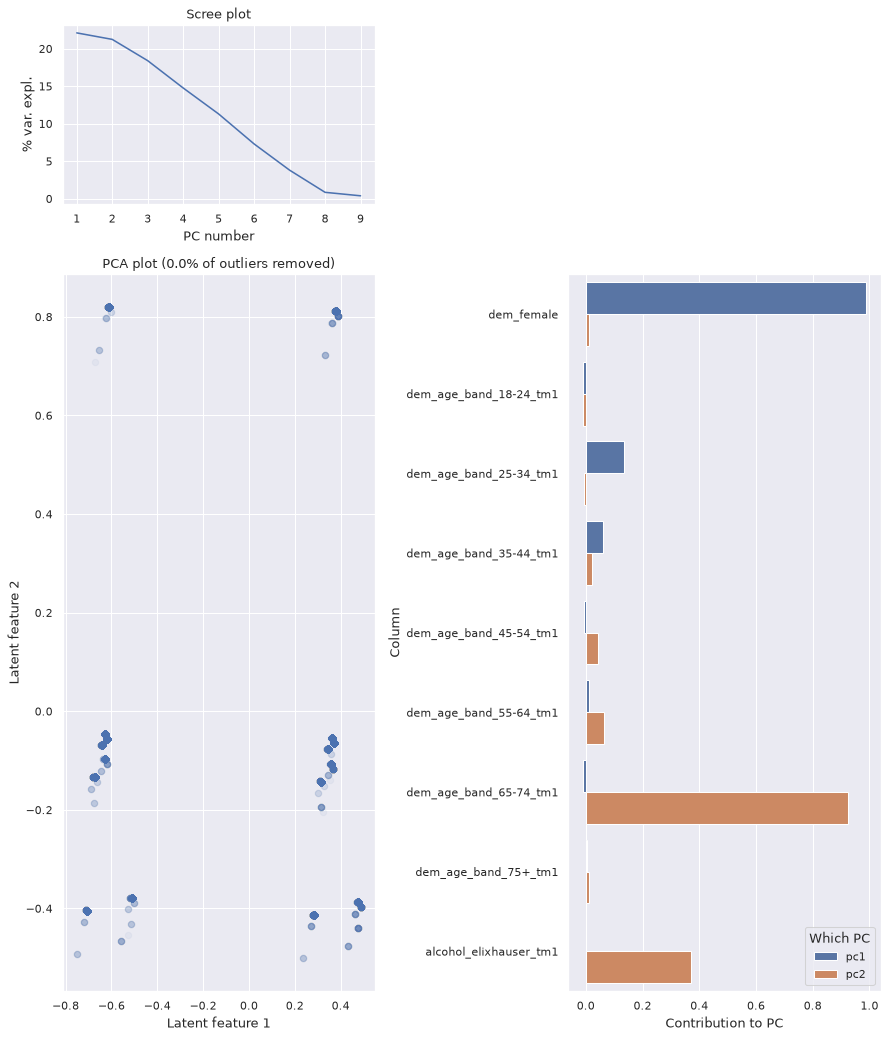

In [7]:
visualize_pca(demographics);

0.8975483765168908


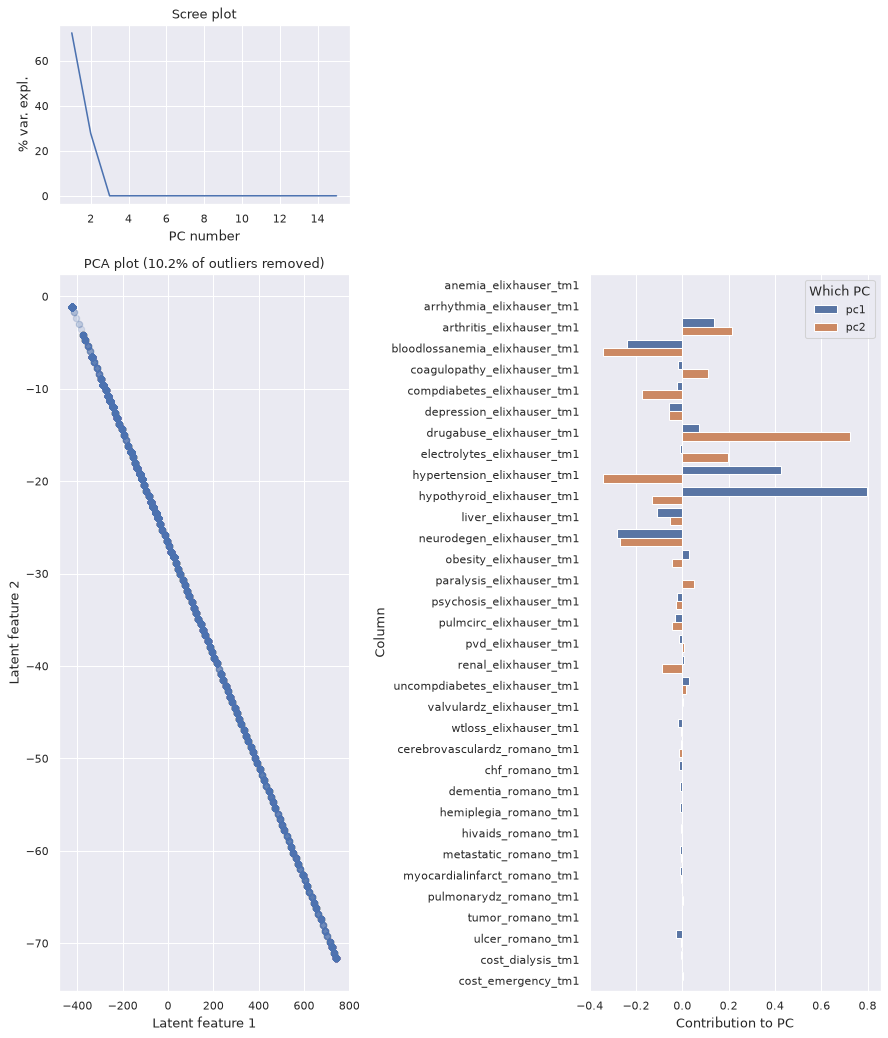

In [8]:
pca_comr, comr = visualize_pca(comorbidities)

0.8903943916038045


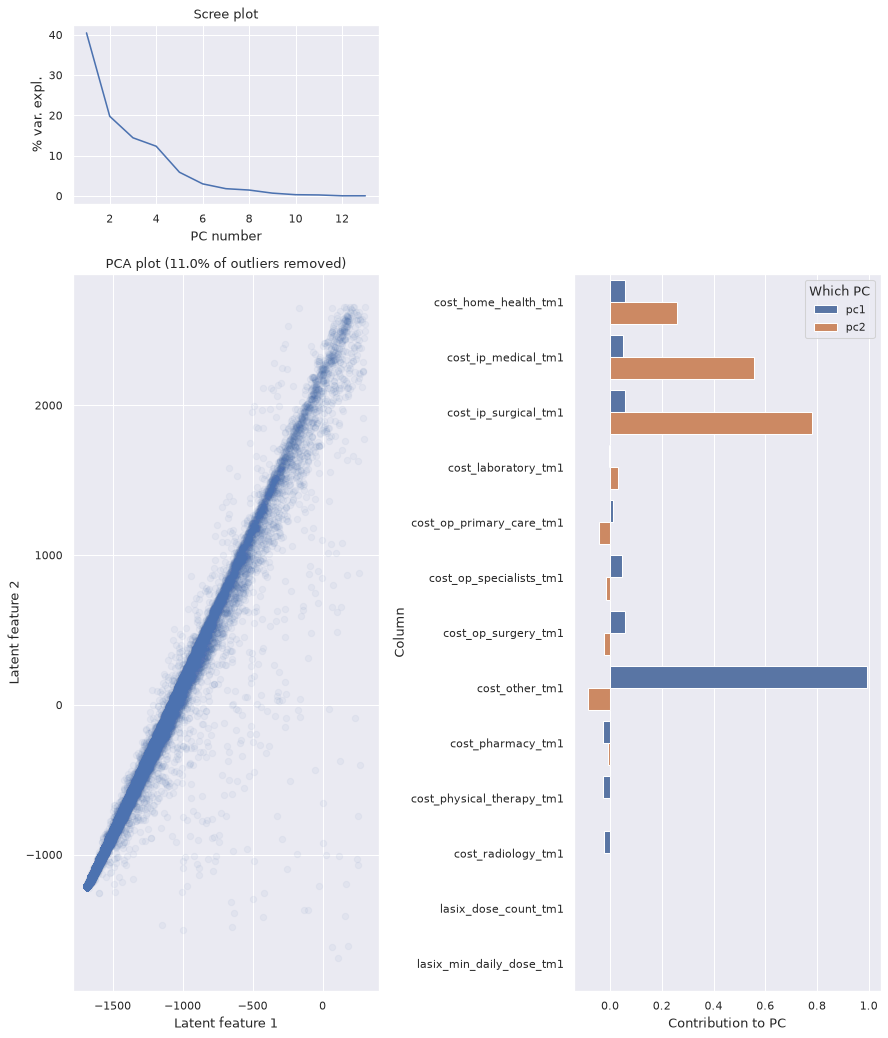

In [9]:
cost_pca, cost_latent = visualize_pca(costs)

0.9367005575598557


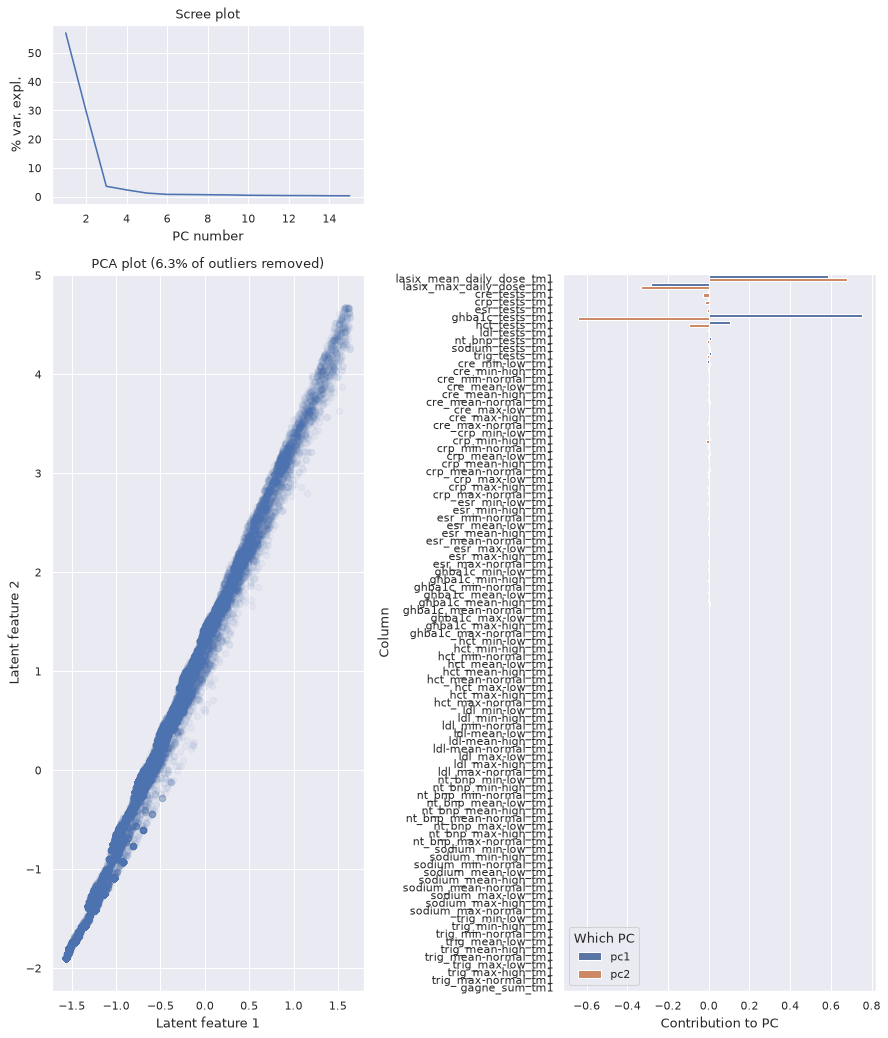

In [10]:
bm_pca, bm_latent = visualize_pca(biomarkers_meds)

## Prediction

### Predicting cost

In [11]:
def make_hist(column, bins, percentile_lines=[90, 95]):
    data = column.to_numpy()
    name = column.name
    f, ax = plt.subplots(1, 1, figsize=(7, 4), dpi=75)
    ax.hist(data, bins=bins, density=True)
    for line_loc in np.percentile(data, percentile_lines):
        plt.axvline(line_loc, ls='--', color='black')
    ax.set_ylabel('Density')
    ax.set_xlabel(name)
    pctile_descr = ', '.join(map(str, percentile_lines))
    ax.set_title(f'Histogram of {name} with percentiles: {pctile_descr}')

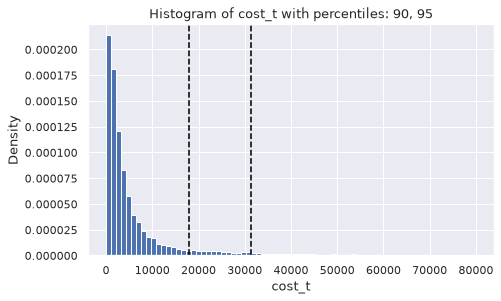

In [12]:
make_hist(patients['cost_t'], bins=np.linspace(0, 80000, 75))

In [13]:
X_START_IDX = 10

def get_X(df):
    return df[:, X_START_IDX:-1] # exclude _t variables since they leak information

def get_y(df, y_col='cost_t', y_threshold=18000):
    return (df[y_col] > y_threshold).cast(pl.Int8)

def train_logistic_model(df, y_col='cost_t', y_threshold=18000, ptest=0.4, num_Cs=25):
    df_train, df_test = train_test_split(
        df, test_size=ptest, stratify=get_y(df, y_col, y_threshold)
    )

    X_train, y_train = get_X(df_train), get_y(df_train, y_col, y_threshold)
    X_test, y_test = get_X(df_test), get_y(df_test, y_col, y_threshold)

    scaler = StandardScaler().fit(X_train)
    C_start = l1_min_c(scaler.transform(X_train), y_train, loss='log', fit_intercept=True)
    C_range = 1e4
    Cs = np.logspace(np.log10(C_start), np.log10(C_start * C_range), num_Cs)

    model = make_pipeline(
        StandardScaler(),
        LogisticRegressionCV(
            l1_ratios=(1.0,), Cs=Cs, scoring='neg_log_loss',
            solver='liblinear', use_legacy_attributes=False
        )
    )
    model.fit(X_train, y_train)
    return model, df_train, df_test

In [14]:
def show_roc(model, df, separate_by_race=True, y_col='cost_t',  y_threshold=18000):
    if separate_by_race:
        race_values = ['white', 'black']
    else:
        race_values = ['Any']
    f, ax = plt.subplots(1, 1, figsize=(6, 6), dpi=150)
    for race in race_values:
        if separate_by_race:
            df_by_race = df.filter(pl.col('race') == race)
        else:
            df_by_race = df
        X_r = get_X(df_by_race)
        y_r = get_y(df_by_race)
        yhat = model.predict_proba(X_r)[:, 1]
        fpr, tpr, thresholds = roc_curve(y_r, yhat)
        args = {} if race == 'Any' else {'label': race.capitalize() + f' (N={X_r.shape[0]})'}
        ax.plot(fpr, tpr, lw=2, alpha=0.8, **args)
    ax.plot([0, 1], [0, 1], 'k--', lw=3)
    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')
    ax.set_title(f'ROC curve for predicting {y_col} > {y_threshold}')
    if separate_by_race:
        ax.legend()
    


In [15]:
# Warning: this takes a while! Don't be surprised if this is slow.
model, dftr, dfte = train_logistic_model(patients)

In [16]:
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregressioncv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](149,)","['dem_female','dem_age_band_18-24_tm1','dem_age_band_25-34_tm1',..., 'trig_max-high_tm1','trig_max-normal_tm1','gagne_sum_tm1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,149
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


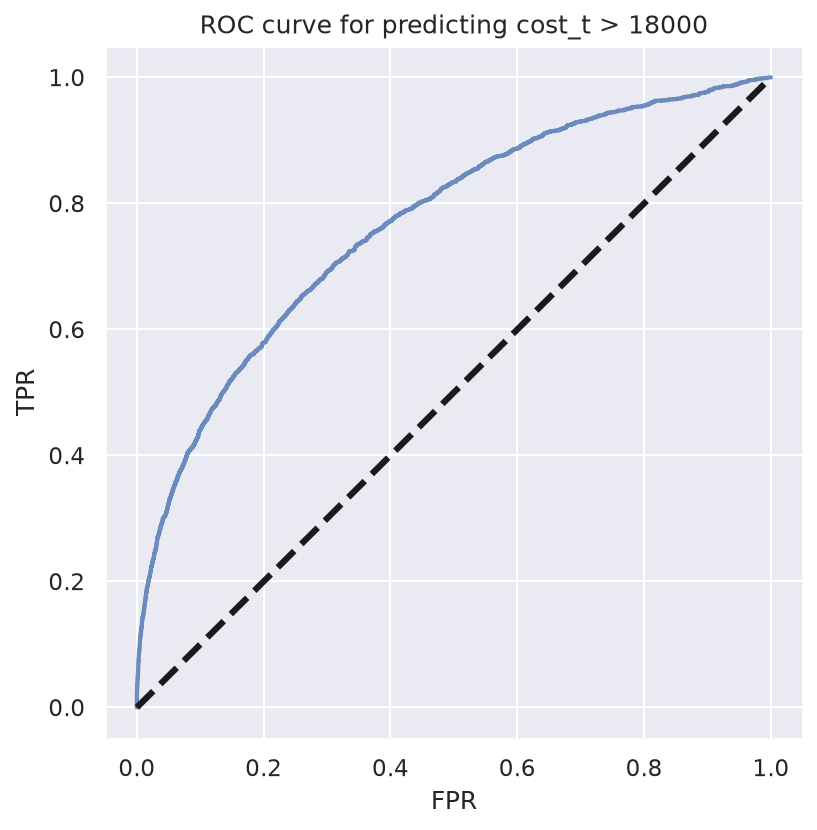

In [17]:
show_roc(model, dfte, separate_by_race=False)

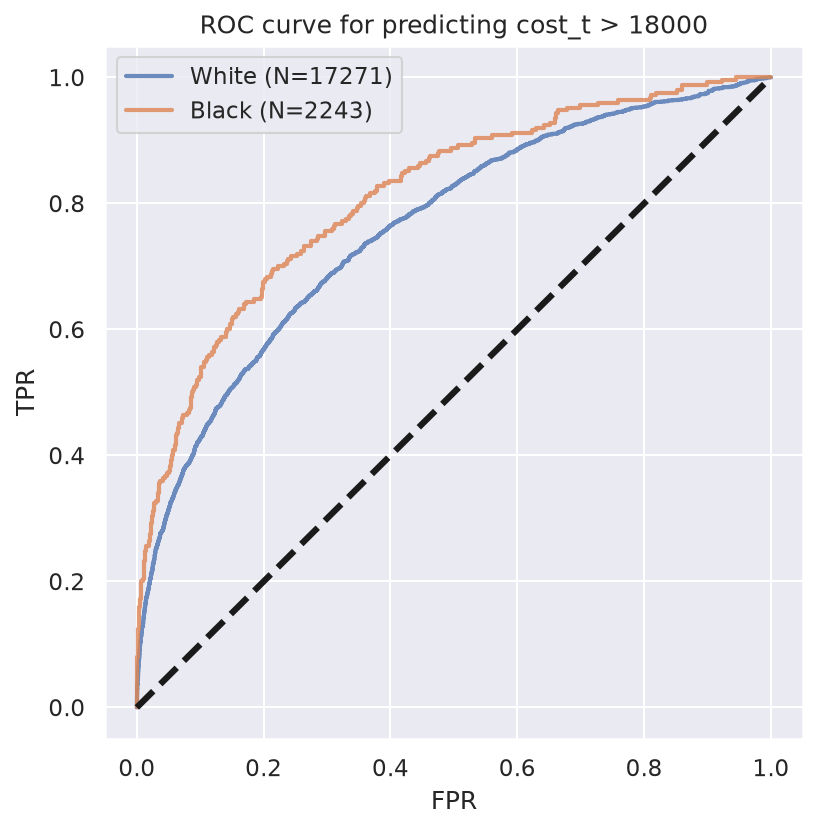

In [18]:
show_roc(model, dfte, separate_by_race=True)

In [19]:
def make_fig1(df, model=None, num_bins=10, xaxis_col='yhat', yaxis_col='gagne_sum_t', pred_col='cost_t'):
    df = df.with_columns(race=pl.col('race').str.to_titlecase())
    if xaxis_col == 'yhat':
        yhat = model.predict_proba(get_X(df))[:, 1]
        df = df.with_columns(yhat=yhat)
    df = df.with_columns(
        (
            df[xaxis_col].bin_ranks(num_bins, labels=False).cast(pl.Float64) / num_bins * 100
        ).alias(f'{xaxis_col} percentile')
    )
    p = sns.lineplot(df.to_pandas(), x=f'{xaxis_col} percentile', y=yaxis_col, hue='race')

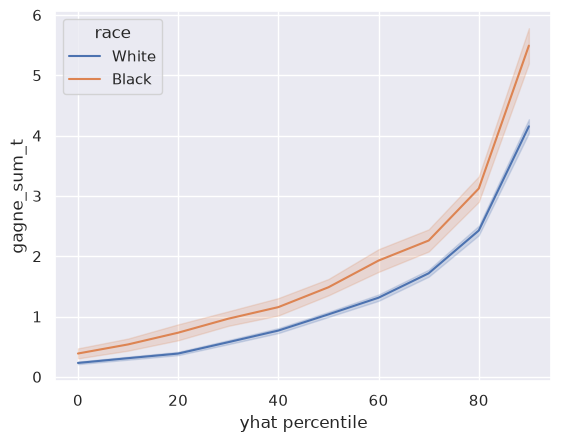

In [20]:
make_fig1(dftr, model, 10, yaxis_col='gagne_sum_t')

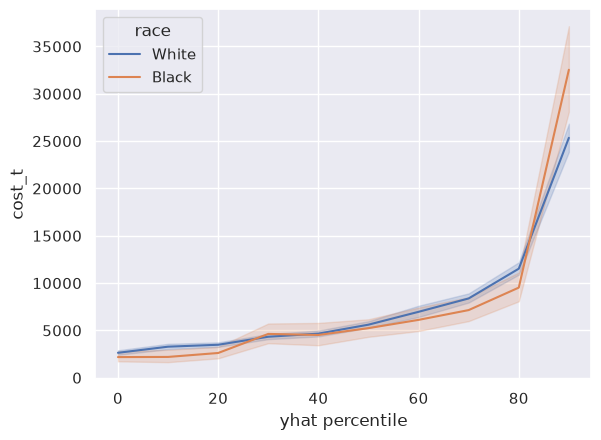

In [21]:
make_fig1(dftr, model, 10, yaxis_col='cost_t')

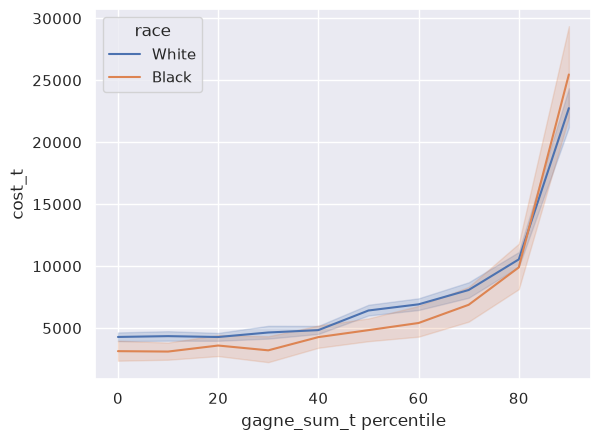

In [22]:
make_fig1(dftr, model, num_bins=10, yaxis_col='cost_t', xaxis_col='gagne_sum_t')

### Predicting health outcomes

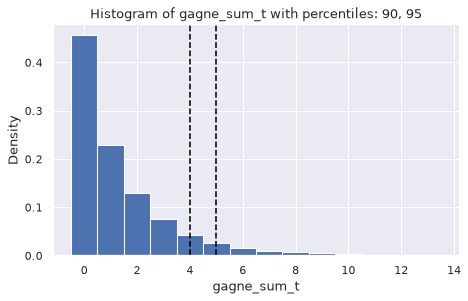

In [23]:
make_hist(patients['gagne_sum_t'], bins=np.arange(15) - 0.5)

In [24]:
# Warning: this takes a while! Don't be surprised if this is slow.
model_gagne, dftr_gagne, dfte_gagne = train_logistic_model(patients, y_col='gagne_sum_t', y_threshold=4)

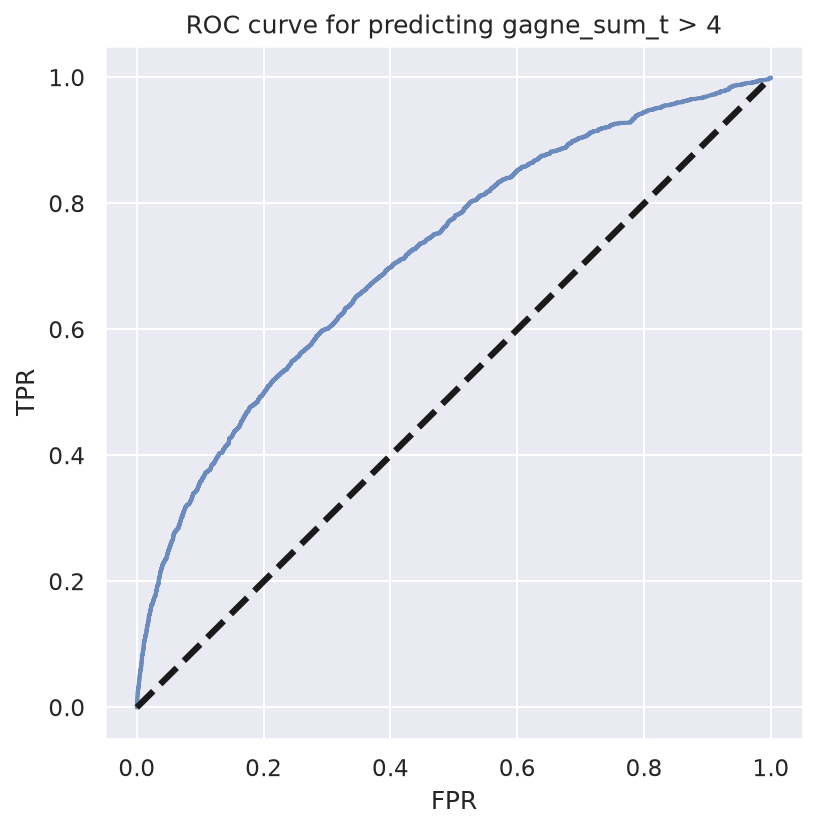

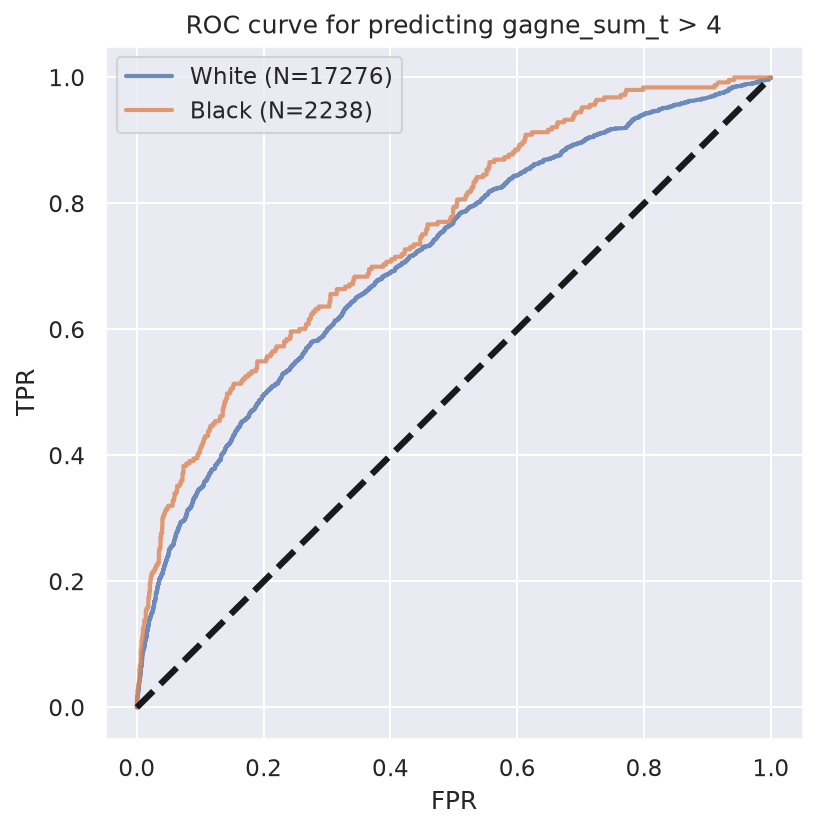

In [25]:
show_roc(model_gagne, dfte_gagne, separate_by_race=False, y_col='gagne_sum_t', y_threshold=4)
show_roc(model_gagne, dfte_gagne, separate_by_race=True, y_col='gagne_sum_t', y_threshold=4)

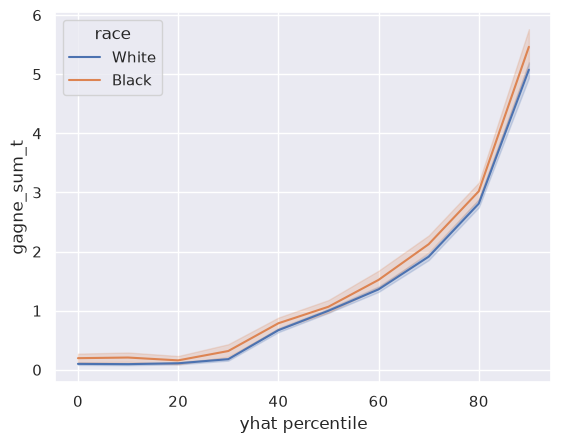

In [26]:
make_fig1(dfte, model_gagne, 10, yaxis_col='gagne_sum_t')